# Practice 6. Data Transformation & EDA



## 0. Dependencies
Run this cell first: it installs any missing libraries (safe to re-run — already installed packages are skipped).

In [1]:
# Install required libraries if they are missing
%pip install -q sqlalchemy seaborn pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 0.1 Setup — create the database and the CSV source
The script below creates the SQLite database (4 related tables with numeric and categorical fields) and a deliberately messy CSV file used later as the ETL source.

In [2]:
%%writefile setup_data.py
"""Setup for Practice 6.
Creates:
  1) shop.db  - SQLite database with 4 related tables (customers, products, orders, order_items)
  2) sales_raw.csv - a messy CSV export from a "second branch", used as the ETL source.
Run:  python setup_data.py
"""
from pathlib import Path

import numpy as np
import pandas as pd
from sqlalchemy import create_engine, text

BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
rng = np.random.default_rng(42)

# ----------------------------------------------------------------------
# 1. Reference tables
# ----------------------------------------------------------------------
customers = pd.DataFrame({
    "customer_id": range(1, 13),
    "name": ["Aigerim S.", "Daulet K.", "Madina T.", "Arman B.", "Aliya N.",
             "Nurlan Zh.", "Dana A.", "Yerlan M.", "Asem O.", "Timur R.",
             "Gulnaz E.", "Bekzat U."],
    "city": ["Almaty", "Astana", "Shymkent", "Karaganda", "Aktobe", "Almaty",
             "Astana", "Almaty", "Shymkent", "Karaganda", None, "Astana"],
    "segment": ["Consumer", "Corporate", "Consumer", "Small Business", "Consumer",
                "Corporate", "Consumer", "Small Business", "Consumer",
                "Corporate", "Consumer", "Small Business"],
    "signup_date": (pd.to_datetime("2024-01-01")
                    + pd.to_timedelta(rng.integers(0, 700, 12), unit="D")),
})

products = pd.DataFrame({
    "product_id": range(1, 11),
    "product_name": ['Laptop 15"', "Wireless Mouse", "Mechanical Keyboard",
                     'Monitor 24"', "USB-C Hub", "Webcam HD", "Desk Lamp",
                     "Notebook Pack", "Headphones", "SSD 1TB"],
    "category": ["Electronics", "Accessories", "Accessories", "Electronics",
                 "Accessories", "Electronics", "Office", "Office",
                 "Electronics", "Electronics"],
    "unit_price": [450000, 8000, 25000, 95000, 12000,
                   18000, 7000, 2500, 30000, 40000],  # KZT
})

# ----------------------------------------------------------------------
# 2. Orders and order items
# ----------------------------------------------------------------------
N_ORDERS = 80
orders = pd.DataFrame({
    "order_id": range(1001, 1001 + N_ORDERS),
    "customer_id": rng.integers(1, 13, N_ORDERS),
    "order_date": (pd.to_datetime("2026-01-01")
                   + pd.to_timedelta(rng.integers(0, 181, N_ORDERS), unit="D")),
    "status": rng.choice(["completed", "cancelled", "returned"],
                         N_ORDERS, p=[0.80, 0.12, 0.08]),
})

rows, item_id = [], 1
for oid in orders["order_id"]:
    k = int(rng.integers(1, 4))                      # 1..3 items per order
    pids = rng.choice(products["product_id"], size=k, replace=False)
    for pid in pids:
        disc = rng.choice([0.0, 0.05, 0.10, 0.15, np.nan],
                          p=[0.50, 0.20, 0.10, 0.10, 0.10])
        rows.append([item_id, oid, int(pid), int(rng.integers(1, 6)), disc])
        item_id += 1
order_items = pd.DataFrame(rows, columns=["item_id", "order_id", "product_id",
                                          "quantity", "discount"])

# ----------------------------------------------------------------------
# 3. Create the database (DDL with foreign keys, then INSERT via pandas)
# ----------------------------------------------------------------------
engine = create_engine(f"sqlite:///{BASE / 'shop.db'}")
ddl = [
    "DROP TABLE IF EXISTS order_items",
    "DROP TABLE IF EXISTS orders",
    "DROP TABLE IF EXISTS products",
    "DROP TABLE IF EXISTS customers",
    """CREATE TABLE customers (
        customer_id INTEGER PRIMARY KEY,
        name        TEXT NOT NULL,
        city        TEXT,
        segment     TEXT NOT NULL,
        signup_date TEXT)""",
    """CREATE TABLE products (
        product_id   INTEGER PRIMARY KEY,
        product_name TEXT NOT NULL,
        category     TEXT NOT NULL,
        unit_price   REAL NOT NULL)""",
    """CREATE TABLE orders (
        order_id    INTEGER PRIMARY KEY,
        customer_id INTEGER NOT NULL REFERENCES customers(customer_id),
        order_date  TEXT NOT NULL,
        status      TEXT NOT NULL)""",
    """CREATE TABLE order_items (
        item_id    INTEGER PRIMARY KEY,
        order_id   INTEGER NOT NULL REFERENCES orders(order_id),
        product_id INTEGER NOT NULL REFERENCES products(product_id),
        quantity   INTEGER NOT NULL,
        discount   REAL)""",
]
with engine.begin() as conn:
    conn.execute(text("PRAGMA foreign_keys = ON"))
    for stmt in ddl:
        conn.execute(text(stmt))

db_customers = customers.assign(signup_date=customers["signup_date"].dt.strftime("%Y-%m-%d"))
db_orders = orders.assign(order_date=orders["order_date"].dt.strftime("%Y-%m-%d"))
db_customers.to_sql("customers", engine, if_exists="append", index=False)
products.to_sql("products", engine, if_exists="append", index=False)
db_orders.to_sql("orders", engine, if_exists="append", index=False)
order_items.to_sql("order_items", engine, if_exists="append", index=False)

with engine.connect() as conn:
    counts = {t: conn.execute(text(f"SELECT COUNT(*) FROM {t}")).scalar()
              for t in ["customers", "products", "orders", "order_items"]}
print("Database created:", BASE / "shop.db")
print("Rows per table:", counts)

# ----------------------------------------------------------------------
# 4. Messy CSV export from the second branch -> ETL source
# ----------------------------------------------------------------------
N = 120
pidx = rng.integers(0, len(products), N)
raw = pd.DataFrame({
    "Order ID": [f"B-{2001 + i}" for i in range(N)],
    "Customer Name": rng.choice(customers["name"], N),
    "City": rng.choice(["Almaty", "almaty", "Astana", " astana ", "Shymkent",
                        "Karaganda", None], N,
                       p=[0.25, 0.10, 0.20, 0.10, 0.15, 0.10, 0.10]),
    "Product": products["product_name"].to_numpy()[pidx],
    "Category": products["category"].to_numpy()[pidx],
    "Qty": rng.integers(1, 6, N).astype(float),
    "Unit Price": products["unit_price"].to_numpy()[pidx].astype(float),
    "Discount %": rng.choice([0.0, 0.05, 0.10, np.nan], N,
                             p=[0.45, 0.20, 0.10, 0.25]),
    "Order Date": (pd.to_datetime("2026-07-01")
                   + pd.to_timedelta(rng.integers(0, 92, N), unit="D")).strftime("%Y-%m-%d"),
    "Status": rng.choice(["Completed", "completed", "Cancelled", "Returned"],
                         N, p=[0.55, 0.20, 0.15, 0.10]),
    "Notes": [None] * N,                      # useless empty column
})
raw.loc[rng.choice(N, 5, replace=False), "Qty"] = np.nan   # missing quantities
raw = pd.concat([raw, raw.iloc[[7, 40, 88]]], ignore_index=True)  # 3 duplicate rows
raw.to_csv(BASE / "sales_raw.csv", index=False)

print("CSV source created:", BASE / "sales_raw.csv", "| shape:", raw.shape)
print("Missing values in CSV:\n", raw.isna().sum().to_string())


Writing setup_data.py


In [3]:
%run setup_data.py

Database created: C:\Users\Acer\Desktop\Data_Collection_Lab6\shop.db
Rows per table: {'customers': 12, 'products': 10, 'orders': 80, 'order_items': 148}
CSV source created: C:\Users\Acer\Desktop\Data_Collection_Lab6\sales_raw.csv | shape: (123, 11)
Missing values in CSV:
 Order ID           0
Customer Name      0
City              11
Product            0
Category           0
Qty                5
Unit Price         0
Discount %        36
Order Date         0
Status             0
Notes            123


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sqlalchemy import create_engine, inspect, text

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
print("pandas", pd.__version__)

pandas 3.0.5


## Task 1. Database connection
Connect with SQLAlchemy, list the tables, load one table into a DataFrame and inspect rows, columns and dtypes.

In [5]:
engine = create_engine("sqlite:///shop.db")
inspector = inspect(engine)
tables = inspector.get_table_names()
print("Available tables:", tables)
for t in tables:
    cols = [c["name"] for c in inspector.get_columns(t)]
    print(f"  {t}: {cols}")

Available tables: ['customers', 'order_items', 'orders', 'products']
  customers: ['customer_id', 'name', 'city', 'segment', 'signup_date']
  order_items: ['item_id', 'order_id', 'product_id', 'quantity', 'discount']
  orders: ['order_id', 'customer_id', 'order_date', 'status']
  products: ['product_id', 'product_name', 'category', 'unit_price']


In [6]:
orders = pd.read_sql_table("orders", engine)
print("Shape (rows, columns):", orders.shape)
print("Column names:", orders.columns.tolist())
print("\nData types:\n", orders.dtypes)
orders.head()

Shape (rows, columns): (80, 4)
Column names: ['order_id', 'customer_id', 'order_date', 'status']

Data types:
 order_id       int64
customer_id    int64
order_date       str
status           str
dtype: object


,order_id,customer_id,order_date,status
0,1001,9,2026-06-02,completed
1,1002,10,2026-03-12,completed
2,1003,9,2026-06-12,completed
3,1004,10,2026-02-22,completed
4,1005,7,2026-02-13,completed


In [7]:
# order_date is stored as TEXT in SQLite -> convert to datetime
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     80 non-null     int64         
 1   customer_id  80 non-null     int64         
 2   order_date   80 non-null     datetime64[us]
 3   status       80 non-null     str           
dtypes: datetime64[us](1), int64(2), str(1)
memory usage: 2.6 KB


## Task 2. SQL queries
Four queries: **WHERE**, **ORDER BY**, **GROUP BY** and a **JOIN** of four tables. All results are loaded into Pandas DataFrames.

In [8]:
# Query 1: WHERE + ORDER BY — expensive products
q1 = """
SELECT product_name, category, unit_price
FROM products
WHERE unit_price >= 20000
ORDER BY unit_price DESC
"""
df_expensive = pd.read_sql_query(q1, engine)
df_expensive

,product_name,category,unit_price
0,"Laptop 15""",Electronics,"450,000.00"
1,"Monitor 24""",Electronics,"95,000.00"
2,SSD 1TB,Electronics,"40,000.00"
3,Headphones,Electronics,"30,000.00"
4,Mechanical Keyboard,Accessories,"25,000.00"


In [9]:
# Query 2: WHERE + ORDER BY — completed orders since April 2026
q2 = """
SELECT order_id, customer_id, order_date, status
FROM orders
WHERE status = 'completed' AND order_date >= '2026-04-01'
ORDER BY order_date DESC
"""
df_recent = pd.read_sql_query(q2, engine)
print("Rows:", len(df_recent))
df_recent.head()

Rows: 33


,order_id,customer_id,order_date,status
0,1069,12,2026-06-30,completed
1,1053,5,2026-06-29,completed
2,1049,12,2026-06-27,completed
3,1061,6,2026-06-16,completed
4,1003,9,2026-06-12,completed


In [10]:
# Query 3: GROUP BY — number of orders per status
q3 = """
SELECT status, COUNT(*) AS orders_count
FROM orders
GROUP BY status
ORDER BY orders_count DESC
"""
df_status = pd.read_sql_query(q3, engine)
df_status

,status,orders_count
0,completed,69
1,cancelled,6
2,returned,5


In [11]:
# Query 4: JOIN — full sales fact table (order_items + orders + customers + products)
q4 = """
SELECT oi.item_id, o.order_id, o.order_date, o.status,
       c.name AS customer_name, c.city, c.segment,
       p.product_name, p.category,
       oi.quantity, p.unit_price, oi.discount
FROM order_items oi
JOIN orders    o ON oi.order_id    = o.order_id
JOIN customers c ON o.customer_id  = c.customer_id
JOIN products  p ON oi.product_id  = p.product_id
"""
sales = pd.read_sql_query(q4, engine)
print("Joined result:", sales.shape)
sales.head()

Joined result: (148, 12)


,item_id,order_id,order_date,status,customer_name,city,segment,product_name,category,quantity,unit_price,discount
0,1,1001,2026-06-02,completed,Asem O.,Shymkent,Consumer,Headphones,Electronics,5,"30,000.00",0.15
1,2,1002,2026-03-12,completed,Timur R.,Karaganda,Corporate,Mechanical Keyboard,Accessories,5,"25,000.00",0.00
2,3,1003,2026-06-12,completed,Asem O.,Shymkent,Consumer,SSD 1TB,Electronics,1,"40,000.00",NaN
3,4,1003,2026-06-12,completed,Asem O.,Shymkent,Consumer,USB-C Hub,Accessories,1,"12,000.00",0.00
4,5,1004,2026-02-22,completed,Timur R.,Karaganda,Corporate,USB-C Hub,Accessories,1,"12,000.00",NaN


## Task 3. Data transformation
Prepare the JOIN result (`sales`) for analysis: handle missing values, fix dtypes, create new columns, remove unnecessary records and columns.

In [12]:
print("Missing values BEFORE cleaning:\n", sales.isna().sum())
print("\nShape before:", sales.shape)

Missing values BEFORE cleaning:
 item_id           0
order_id          0
order_date        0
status            0
customer_name     0
city              9
segment           0
product_name      0
category          0
quantity          0
unit_price        0
discount         18
dtype: int64

Shape before: (148, 12)


In [13]:
clean = sales.copy()

# 1) Missing values: no discount recorded -> 0; unknown city -> 'Unknown'
clean["discount"] = clean["discount"].fillna(0.0)
clean["city"] = clean["city"].fillna("Unknown")

# 2) Data types
clean["order_date"] = pd.to_datetime(clean["order_date"])
clean["quantity"] = clean["quantity"].astype(int)

# 3) Remove unnecessary records: keep only completed orders (real sales)
clean = clean[clean["status"] == "completed"]

# 4) New columns: revenue per line and month
clean["revenue"] = (clean["quantity"] * clean["unit_price"] * (1 - clean["discount"])).round(2)
clean["month"] = clean["order_date"].dt.to_period("M").astype(str)

# 5) Drop unnecessary columns (item_id is a technical key, status is constant now)
clean = clean.drop(columns=["item_id", "status"]).reset_index(drop=True)

print("Missing values AFTER cleaning:", int(clean.isna().sum().sum()))
print("Shape after:", clean.shape)
clean.head()

Missing values AFTER cleaning: 0
Shape after: (131, 12)


,order_id,order_date,customer_name,city,segment,product_name,category,quantity,unit_price,discount,revenue,month
0,1001,2026-06-02,Asem O.,Shymkent,Consumer,Headphones,Electronics,5,"30,000.00",0.15,"127,500.00",2026-06
1,1002,2026-03-12,Timur R.,Karaganda,Corporate,Mechanical Keyboard,Accessories,5,"25,000.00",0.00,"125,000.00",2026-03
2,1003,2026-06-12,Asem O.,Shymkent,Consumer,SSD 1TB,Electronics,1,"40,000.00",0.00,"40,000.00",2026-06
3,1003,2026-06-12,Asem O.,Shymkent,Consumer,USB-C Hub,Accessories,1,"12,000.00",0.00,"12,000.00",2026-06
4,1004,2026-02-22,Timur R.,Karaganda,Corporate,USB-C Hub,Accessories,1,"12,000.00",0.00,"12,000.00",2026-02


In [14]:
clean.dtypes.to_frame("dtype")

,dtype
order_id,int64
order_date,datetime64[us]
customer_name,str
city,str
segment,str
product_name,str
category,str
quantity,int64
unit_price,float64
discount,float64


## EDA — GroupBy, merge, pivot/melt and plots
(Required by the practice title: Pandas GroupBy, joins, reshaping + Matplotlib/Seaborn.)

In [15]:
# GroupBy: revenue and units per category
cat_rev = (clean.groupby("category")
           .agg(revenue=("revenue", "sum"),
                units=("quantity", "sum"),
                lines=("order_id", "count"))
           .reset_index()
           .sort_values("revenue", ascending=False))
cat_rev

,category,revenue,units,lines
1,Electronics,"19,995,250.00",203,68
0,Accessories,"1,748,800.00",124,39
2,Office,"374,250.00",77,24


In [16]:
# Pandas merge (join): attach category totals to the product catalogue
products = pd.read_sql_table("products", engine)
prod_with_cat = products.merge(cat_rev[["category", "revenue"]], on="category", how="left")
prod_with_cat = prod_with_cat.rename(columns={"revenue": "category_total_revenue"})
prod_with_cat.head()

,product_id,product_name,category,unit_price,category_total_revenue
0,1,"Laptop 15""",Electronics,"450,000.00","19,995,250.00"
1,2,Wireless Mouse,Accessories,"8,000.00","1,748,800.00"
2,3,Mechanical Keyboard,Accessories,"25,000.00","1,748,800.00"
3,4,"Monitor 24""",Electronics,"95,000.00","19,995,250.00"
4,5,USB-C Hub,Accessories,"12,000.00","1,748,800.00"


In [17]:
# Pivot: month x category revenue matrix
pivot = clean.pivot_table(index="month", columns="category",
                          values="revenue", aggfunc="sum", fill_value=0)
pivot

category,Accessories,Electronics,Office
month,,,
2026-01,"438,250.00","4,224,000.00","90,125.00"
2026-02,"210,750.00","1,958,500.00","105,000.00"
2026-03,"335,600.00","4,318,000.00","19,400.00"
2026-04,"326,200.00","3,522,650.00","89,100.00"
2026-05,"221,600.00","4,291,500.00","12,500.00"
2026-06,"216,400.00","1,680,600.00","58,125.00"


In [18]:
# Melt: wide pivot back to long format
long = pivot.reset_index().melt(id_vars="month", var_name="category", value_name="revenue")
print("Wide shape:", pivot.shape, "| Long shape:", long.shape)
long.head()

Wide shape: (6, 3) | Long shape: (18, 3)


,month,category,revenue
0,2026-01,Accessories,"438,250.00"
1,2026-02,Accessories,"210,750.00"
2,2026-03,Accessories,"335,600.00"
3,2026-04,Accessories,"326,200.00"
4,2026-05,Accessories,"221,600.00"


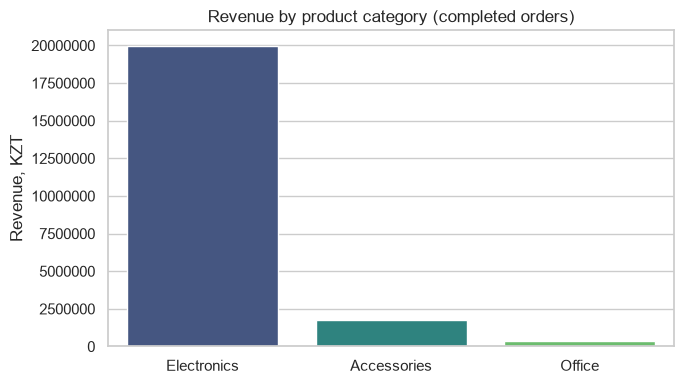

In [19]:
# Plot 1 (Seaborn): revenue by category
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=cat_rev, x="category", y="revenue", hue="category",
            palette="viridis", legend=False, ax=ax)
ax.set_title("Revenue by product category (completed orders)")
ax.set_xlabel(""); ax.set_ylabel("Revenue, KZT")
ax.ticklabel_format(axis="y", style="plain")
fig.tight_layout(); fig.savefig(FIG / "revenue_by_category.png", dpi=150)
plt.show()

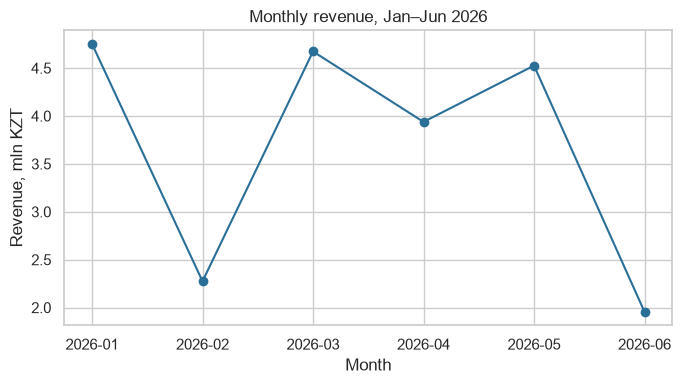

In [20]:
# Plot 2 (Matplotlib): monthly revenue dynamics
monthly = clean.groupby("month")["revenue"].sum()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(monthly.index, monthly.values / 1e6, marker="o", color="#2a6f97")
ax.set_title("Monthly revenue, Jan–Jun 2026")
ax.set_xlabel("Month"); ax.set_ylabel("Revenue, mln KZT")
fig.tight_layout(); fig.savefig(FIG / "monthly_revenue.png", dpi=150)
plt.show()

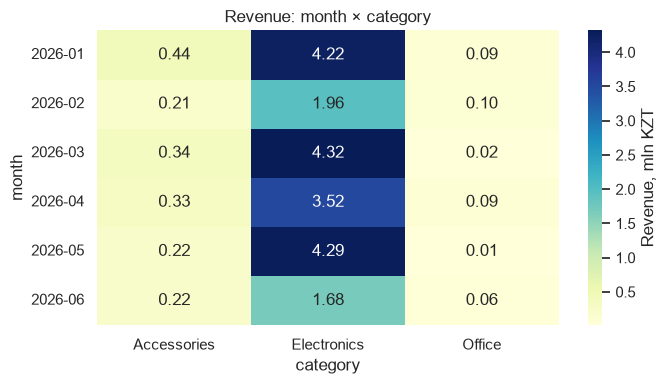

In [21]:
# Plot 3 (Seaborn): heatmap of the pivot table
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(pivot / 1e6, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax,
            cbar_kws={"label": "Revenue, mln KZT"})
ax.set_title("Revenue: month × category")
fig.tight_layout(); fig.savefig(FIG / "heatmap.png", dpi=150)
plt.show()

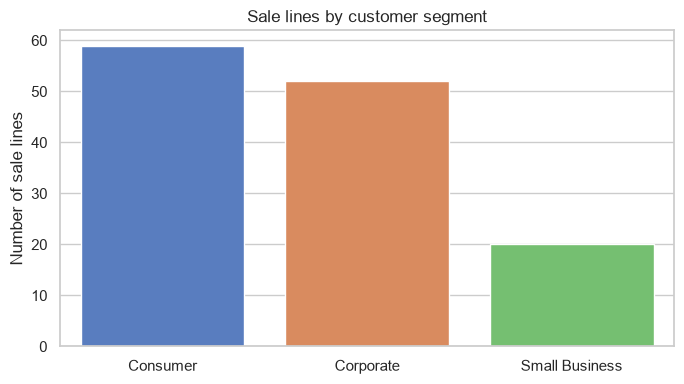

In [22]:
# Plot 4 (Seaborn): number of sale lines per customer segment
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=clean, x="segment", hue="segment", palette="muted", legend=False, ax=ax)
ax.set_title("Sale lines by customer segment")
ax.set_xlabel(""); ax.set_ylabel("Number of sale lines")
fig.tight_layout(); fig.savefig(FIG / "segments.png", dpi=150)
plt.show()

## Task 4. ETL pipeline
One script, one sequence: **CSV source → processed DataFrame → database table → read-back check**.
The script `etl_pipeline.py` performs: *Extract* (read CSV) → *Transform* (rename/drop columns, normalize text, fix types, fill missing values, remove duplicates/cancelled/invalid rows, create `revenue`) → *Load* (`to_sql` into table `branch_sales`) → *Verify* (read back, print rows).

In [23]:
%%writefile etl_pipeline.py
"""Task 4. ETL pipeline: sales_raw.csv -> pandas DataFrame -> SQLite table.

Extract   : read the messy CSV export of the second branch.
Transform : rename/drop columns, fix types, fill missing values,
            normalize text, remove duplicates and invalid rows,
            create the derived column `revenue`.
Load      : write the cleaned DataFrame to the SQLite table `branch_sales`
            using SQLAlchemy.
Verify    : read the table back and print several rows.

Run:  python etl_pipeline.py
"""
from pathlib import Path

import pandas as pd
from sqlalchemy import create_engine

BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DB_PATH = BASE / "shop.db"
SOURCE = BASE / "sales_raw.csv"
TABLE = "branch_sales"

RENAME = {
    "Order ID": "order_id", "Customer Name": "customer_name", "City": "city",
    "Product": "product", "Category": "category", "Qty": "qty",
    "Unit Price": "unit_price", "Discount %": "discount",
    "Order Date": "order_date", "Status": "status", "Notes": "notes",
}


def extract(path: Path = SOURCE) -> pd.DataFrame:
    df = pd.read_csv(path)
    print(f"[EXTRACT]   {len(df)} rows x {df.shape[1]} columns read from {path.name}")
    return df


def transform(df: pd.DataFrame) -> pd.DataFrame:
    n0 = len(df)
    df = df.rename(columns=RENAME)                 # 1) snake_case names
    df = df.drop(columns=["notes"])                # 2) drop useless column

    df["city"] = df["city"].str.strip().str.title().fillna("Unknown")   # 3) normalize
    df["status"] = df["status"].str.strip().str.lower()

    df["qty"] = pd.to_numeric(df["qty"], errors="coerce")               # 4) fix types
    df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
    df["discount"] = pd.to_numeric(df["discount"], errors="coerce").fillna(0.0)
    df["order_date"] = pd.to_datetime(df["order_date"], format="%Y-%m-%d")

    df = df.drop_duplicates()                      # 5) remove duplicate rows
    n_dup = n0 - len(df)
    df = df[df["status"] != "cancelled"]           # 6) keep only real sales
    n_cancel = n0 - n_dup - len(df)
    df = df[df["qty"].notna() & (df["qty"] > 0)]   # 7) rows without a valid qty
    n_bad = n0 - n_dup - n_cancel - len(df)
    df["qty"] = df["qty"].astype(int)

    df["revenue"] = (df["qty"] * df["unit_price"] * (1 - df["discount"])).round(2)  # 8) new column
    df = df.reset_index(drop=True)
    print(f"[TRANSFORM] removed: {n_dup} duplicates, {n_cancel} cancelled, "
          f"{n_bad} invalid-qty rows -> {len(df)} clean rows")
    return df


def load(df: pd.DataFrame, table: str = TABLE) -> None:
    engine = create_engine(f"sqlite:///{DB_PATH}")
    df.to_sql(table, engine, if_exists="replace", index=False)
    print(f"[LOAD]      {len(df)} rows written to table '{table}' in {DB_PATH.name}")


def verify(table: str = TABLE) -> pd.DataFrame:
    engine = create_engine(f"sqlite:///{DB_PATH}")
    back = pd.read_sql_table(table, engine, parse_dates=["order_date"])
    print(f"[VERIFY]    read back {len(back)} rows. First 5 rows:")
    print(back.head().to_string(index=False))
    print(f"[VERIFY]    total revenue in DB: {back['revenue'].sum():,.0f} KZT")
    return back


def main() -> pd.DataFrame:
    raw = extract()
    clean = transform(raw)
    load(clean)
    return verify()


if __name__ == "__main__":
    main()


Writing etl_pipeline.py


In [24]:
%run etl_pipeline.py

[EXTRACT]   123 rows x 11 columns read from sales_raw.csv
[TRANSFORM] removed: 3 duplicates, 17 cancelled, 5 invalid-qty rows -> 98 clean rows
[LOAD]      98 rows written to table 'branch_sales' in shop.db
[VERIFY]    read back 98 rows. First 5 rows:
order_id customer_name      city        product    category  qty  unit_price  discount order_date    status   revenue
  B-2001     Madina T. Karaganda  Notebook Pack      Office    3    2,500.00      0.00 2026-07-01 completed  7,500.00
  B-2003       Dana A.    Astana      USB-C Hub Accessories    3   12,000.00      0.00 2026-07-31 completed 36,000.00
  B-2004     Yerlan M.    Astana Wireless Mouse Accessories    1    8,000.00      0.05 2026-08-17 completed  7,600.00
  B-2006     Bekzat U. Karaganda Wireless Mouse Accessories    4    8,000.00      0.00 2026-08-15 completed 32,000.00
  B-2007      Timur R.    Almaty      USB-C Hub Accessories    5   12,000.00      0.05 2026-08-11  returned 57,000.00
[VERIFY]    total revenue in DB: 15,724,0

## Task 5. Data check — source vs final table
Read `branch_sales` back from the database and compare it with the raw CSV: number of records, missing values, duplicates, data types.

In [25]:
raw = pd.read_csv("sales_raw.csv")
final = pd.read_sql_table("branch_sales", engine, parse_dates=["order_date"])

print("Source rows:", len(raw), "| Final rows:", len(final))
print("Removed rows:", len(raw) - len(final))
print("  duplicates in source:", int(raw.duplicated().sum()))
print("  cancelled in source :", int(raw['Status'].str.strip().str.lower().eq('cancelled').sum()))
print("  invalid/missing Qty :", int(raw['Qty'].isna().sum()))

Source rows: 123 | Final rows: 98
Removed rows: 25
  duplicates in source: 3
  cancelled in source : 17
  invalid/missing Qty : 5


In [26]:
comparison = pd.DataFrame({
    "Source (sales_raw.csv)": [len(raw), int(raw.isna().sum().sum()),
                               int(raw.duplicated().sum()),
                               str(raw["Order Date"].dtype), str(raw["Qty"].dtype),
                               "absent"],
    "Final (branch_sales)":   [len(final), int(final.isna().sum().sum()),
                               int(final.duplicated().sum()),
                               str(final["order_date"].dtype), str(final["qty"].dtype),
                               "present (float64)"],
}, index=["Rows", "Missing values (total)", "Duplicate rows",
          "Date column dtype", "Qty column dtype", "revenue column"])
comparison

,Source (sales_raw.csv),Final (branch_sales)
Rows,123,98
Missing values (total),175,0
Duplicate rows,3,0
Date column dtype,str,datetime64[us]
Qty column dtype,float64,int64
revenue column,absent,present (float64)


In [27]:
# Integrity checks
recomputed = (final["qty"] * final["unit_price"] * (1 - final["discount"])).round(2)
assert np.allclose(final["revenue"], recomputed), "revenue mismatch!"
assert final.isna().sum().sum() == 0, "missing values remain!"
assert final.duplicated().sum() == 0, "duplicates remain!"
assert not final["status"].eq("cancelled").any(), "cancelled rows remain!"
print("All integrity checks PASSED")
print(f"Total revenue in branch_sales: {final['revenue'].sum():,.0f} KZT")
final.head()

All integrity checks PASSED
Total revenue in branch_sales: 15,724,000 KZT


,order_id,customer_name,city,product,category,qty,unit_price,discount,order_date,status,revenue
0,B-2001,Madina T.,Karaganda,Notebook Pack,Office,3,"2,500.00",0.00,2026-07-01,completed,"7,500.00"
1,B-2003,Dana A.,Astana,USB-C Hub,Accessories,3,"12,000.00",0.00,2026-07-31,completed,"36,000.00"
2,B-2004,Yerlan M.,Astana,Wireless Mouse,Accessories,1,"8,000.00",0.05,2026-08-17,completed,"7,600.00"
3,B-2006,Bekzat U.,Karaganda,Wireless Mouse,Accessories,4,"8,000.00",0.00,2026-08-15,completed,"32,000.00"
4,B-2007,Timur R.,Almaty,USB-C Hub,Accessories,5,"12,000.00",0.05,2026-08-11,returned,"57,000.00"


### Five findings about the ETL process

1. **Row count is fully explained:** the source had 123 rows, the final table has 98. Exactly 25 rows were removed on purpose: 3 full duplicates, 17 cancelled orders and 5 rows with missing quantity — no unexplained data loss.
2. **All missing values were resolved:** 36 missing discounts were filled with 0, missing cities were normalized to `Unknown`, rows with missing `Qty` were dropped, and the fully empty `Notes` column was removed. The final table contains **0 missing values**.
3. **Duplicates were eliminated:** the CSV contained 3 duplicated rows; the final table has **0 duplicates**, so revenue is not double-counted.
4. **Data types were corrected:** `Order Date` (object/string) became `datetime64`, `Qty` (float with NaN) became `int64`, and the new `revenue` column is `float64`. Types survive the round-trip through SQLite (dates are read back with `parse_dates`).
5. **Values are consistent and correct:** the derived `revenue = qty × unit_price × (1 − discount)` matches the stored values for every row; text was normalized (`Completed`/`completed` → `completed`, ` astana ` → `Astana`); total revenue of the branch is **15,724,000 KZT**.

## Conclusion
All five tasks were completed: a relational SQLite database was created and connected via SQLAlchemy; SQL queries with WHERE / ORDER BY / GROUP BY / JOIN were loaded into Pandas; the joined data was cleaned and enriched; GroupBy, merge, pivot/melt and four plots were produced; a full ETL pipeline (CSV → DataFrame → SQLite) was implemented as one script and verified with record-count, missing-value, duplicate, dtype and value-integrity checks.